# Setup

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.constants import DATASETS_DIR
from src.data_loading import load_csv_data, parse_preprocessing_config
from src.dataset_config import load_dataset_config
from src.preprocessing import filter_doublets, normalize_by_library_size, log_transform, normalize_with_pearson
from src.preprocessing.gene_annotation import load_gene_annotation
from src.preprocessing.gene_sets import duplicated_genes, matching_genes, rrna_genes, unmatched_genes
from src.preprocessing.pipeline import run_filtering_pipeline
from src.preprocessing.qc_metrics import cell_qc_metrics
from src.visualization import (
    plot_qc_overview,
    plot_gene_set_qc,
    plot_gene_max_count_distribution,
    plot_normalization_comparison,
    plot_log_transform_comparison,
)

## Data Loading

In [3]:
from src.data_loading import load_csv_data

DATA_PATH = DATASETS_DIR / 'GSE36552' / 'interim' / 'counts.csv.gz'
raw_data = load_csv_data(DATA_PATH)

raw_data

,FSTL1,AACS,RPS11,ELMO2,PNMA1,MMP2,SLMAP,TMEM216,SAMD4A,HAUS2,...,GPX5,SPATA8,CSF2RB,SNORA54,G6PC2,LOC440117,CCT8L2,CXorf66,SERPINA10,SPRR3
cell_id,,,,,,,,,,,,,,,,,,,,,
GSM922271,245,628,21930,2,233,5,1340,297,1,1469,...,0,0,0,0,0,0,0,0,0,0
GSM922256,1629,1287,11959,17,48,26,1364,43,76,382,...,0,0,0,0,0,0,0,0,0,0
GSM922187,0,51,38556,40,3269,15,847,4,95,2474,...,0,0,0,0,0,0,0,0,0,0
GSM922199,14,18,7597,0,765,0,761,0,0,1075,...,0,0,0,0,0,0,0,0,0,0
GSM922150,0,825,84470,4182,205,0,114,340,2260,334,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSM922156,0,1174,45742,6349,230,0,105,325,1661,122,...,0,0,0,0,0,0,0,0,0,0
GSM922178,2,0,26420,320,2039,0,1229,127,0,1340,...,0,0,0,0,0,0,0,0,0,0
GSM922200,2,1,9232,524,411,0,1395,0,0,1149,...,0,0,0,0,0,0,0,0,0,0


## Dataset config

In [4]:
DATASET_DIR = DATASETS_DIR / 'GSE36552'

dataset_config = load_dataset_config(DATASET_DIR / 'config.yaml')
SPECIES = dataset_config["species"]
preprocessing_config = parse_preprocessing_config(dataset_config)

preprocessing_config

PreprocessingConfig(mito_threshold=0.05, min_gene_max_count=2, count_threshold=None, gene_threshold=None)

# Quality Control

In [5]:
qc_metrics = cell_qc_metrics(raw_data, species=SPECIES)

print(qc_metrics.median().round(3))
display(qc_metrics.head(5).round(3))
display(qc_metrics.tail(5).round(3))

None of the 37 mitochondrial genes (matched by name or Ensembl ID) were found in the data columns, so every cell's mitochondrial fraction is 0
None of the 552 rRNA genes (matched by name or Ensembl ID) were found in the data columns, so every cell's rRNA fraction is 0


count_depth           1.779859e+07
n_genes               1.270650e+04
mito_fraction         0.000000e+00
rrna_fraction         0.000000e+00
apoptosis_fraction    1.100000e-02
dtype: float64


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
GSM922148,31416500,12793,0.0,0.0,0.008
GSM922146,30512531,12419,0.0,0.0,0.008
GSM922147,28391110,11935,0.0,0.0,0.008
GSM922175,28380406,13141,0.0,0.0,0.010
GSM922173,28334042,13370,0.0,0.0,0.011


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
GSM922275,8948799,13618,0.0,0.0,0.007
GSM922168,8166313,14057,0.0,0.0,0.012
GSM922184,7834896,12284,0.0,0.0,0.011
GSM922185,4267476,10208,0.0,0.0,0.011
GSM922180,3794394,11455,0.0,0.0,0.009


None of the 37 mitochondrial genes (matched by name or Ensembl ID) were found in the data columns, so every cell's mitochondrial fraction is 0


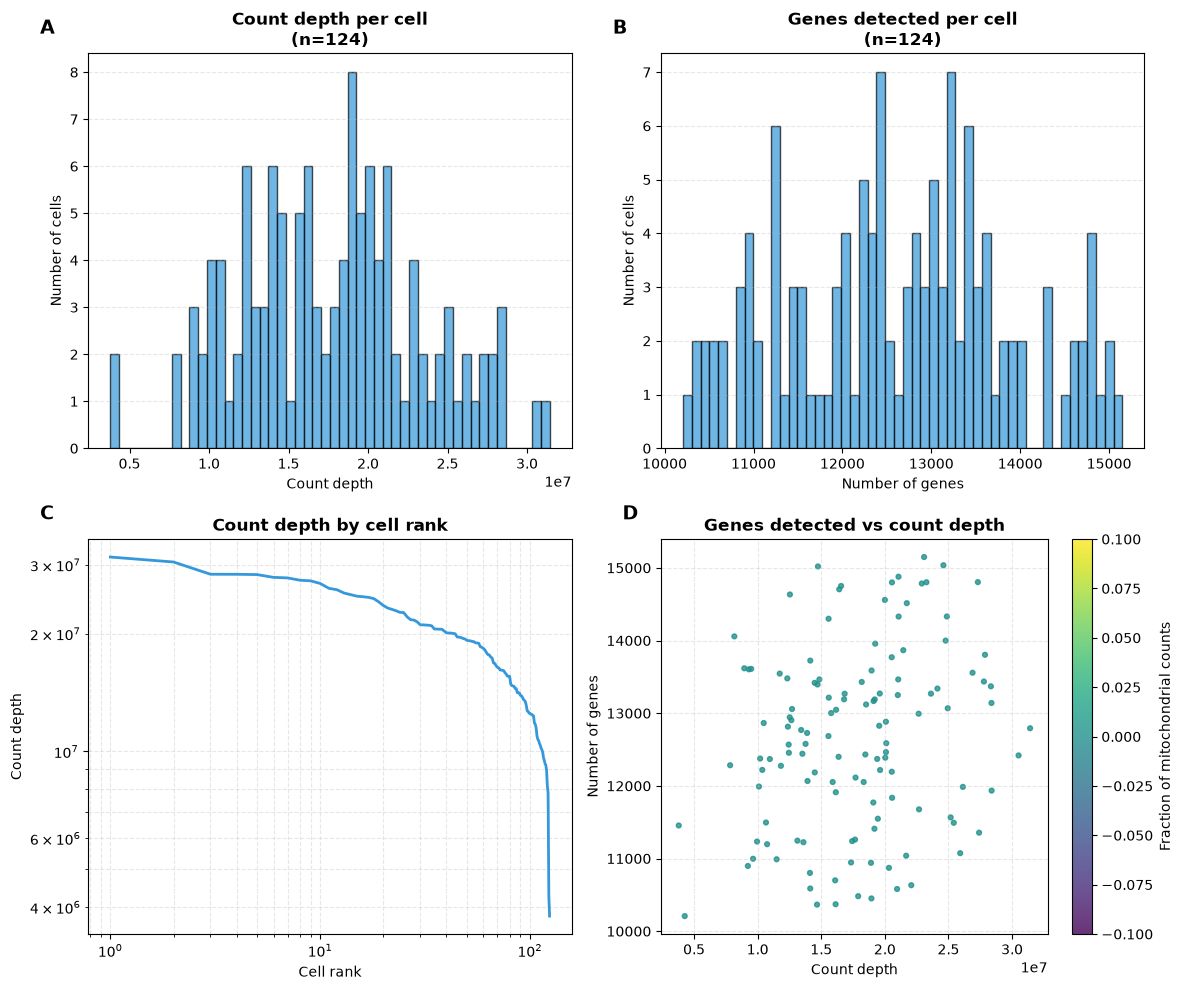

In [6]:
plot_qc_overview(
    raw_data,
    species=SPECIES,
    count_threshold=preprocessing_config.count_threshold,  # minimum count depth, set in the dataset config
    gene_threshold=preprocessing_config.gene_threshold,    # minimum genes per cell, set in the dataset config
)

## Mitochondrial, rRNA and apoptosis fractions

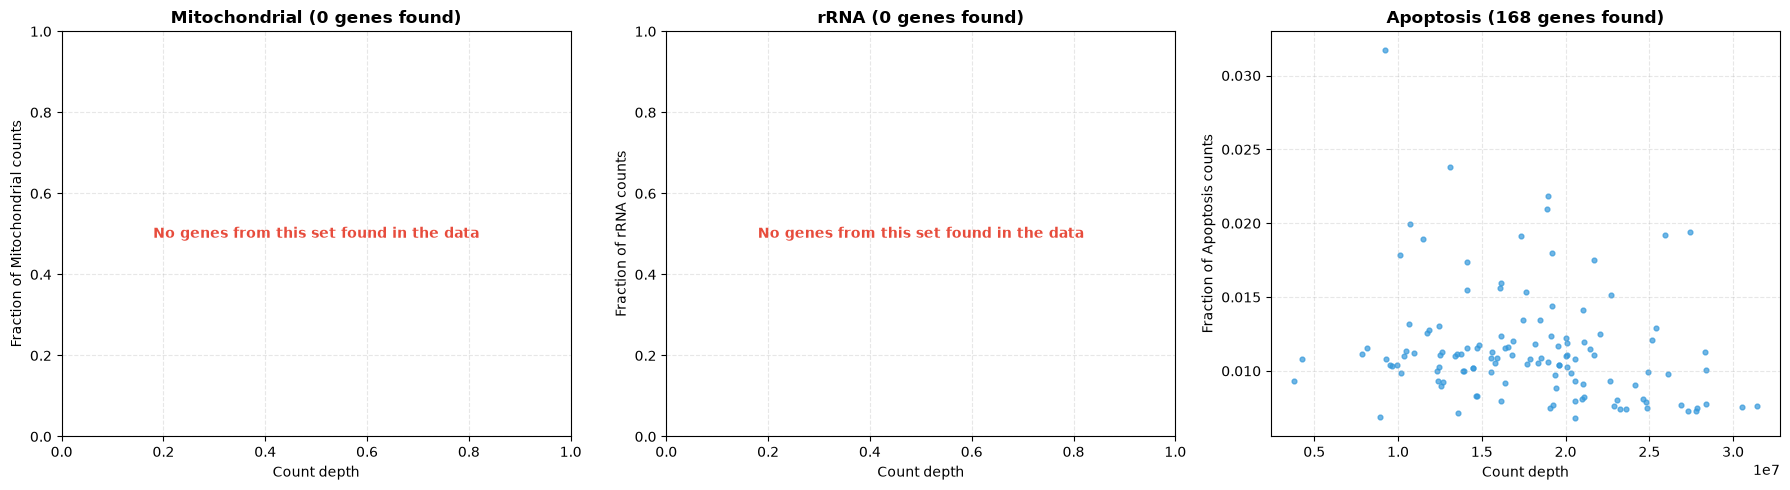

In [7]:
plot_gene_set_qc(raw_data, SPECIES, preprocessing_config)

## Genes

### Uniqueness

In [8]:
duplicates = duplicated_genes(raw_data)

print(f"Gene columns: {raw_data.shape[1]}, unique gene names: {raw_data.columns.nunique()}")
print(f"Gene names appearing in more than one column: {len(duplicates)}")
display(duplicates)

assert duplicates.empty, "Duplicated gene names found, see the table above"

Gene columns: 20286, unique gene names: 20286
Gene names appearing in more than one column: 0


,n_columns,identical_counts
gene,,


### Missing from the annotation

In [9]:
annotation = load_gene_annotation(SPECIES)
unmatched = unmatched_genes(raw_data, annotation)
alias_hits = unmatched.alias_matches
n_alias_genes = alias_hits["gene"].nunique()
n_ambiguous = alias_hits.loc[alias_hits["n_matches"] > 1, "gene"].nunique()

print(f"Genes matching no gene_id or gene_name: {n_alias_genes + len(unmatched.unknown_ensembl_ids) + len(unmatched.other)} / {raw_data.shape[1]}")
print(f"  found through alias_names: {n_alias_genes} ({n_ambiguous} matching more than one annotation row)")
print(f"  Ensembl IDs missing from the annotation: {len(unmatched.unknown_ensembl_ids)}, e.g. {unmatched.unknown_ensembl_ids[:5]}")
print(f"  other: {len(unmatched.other)}, e.g. {unmatched.other[:5]}")
display(alias_hits)

Genes matching no gene_id or gene_name: 3632 / 20286
  found through alias_names: 2601 (31 matching more than one annotation row)
  Ensembl IDs missing from the annotation: 0, e.g. []
  other: 1031, e.g. ['LOC401397', 'LOC100130557', 'IPW', 'LOC100128788', 'DLX6AS']


,gene,n_matches,gene_id,gene_name,gene_biotype,chromosome,MT_status,RB_status,TF_status,APOPT_status,alias_names
0,GIF,3,ENSG00000134812,CBLIF,protein_coding,11,NO_MT,NO_RB,NO_TF,NO_APOPT,CBLIF;GIF;IF;IFMH;INF;TCN3
1,GIF,3,ENSG00000087250,MT3,protein_coding,16,NO_MT,NO_RB,NO_TF,NO_APOPT,GIF;MT3
2,GIF,3,ENSG00000240972,MIF,protein_coding,22,NO_MT,NO_RB,NO_TF,NO_APOPT,GIF;GLIF;MIF
3,NOV,3,ENSG00000114554,PLXNA1,protein_coding,3,NO_MT,NO_RB,NO_TF,NO_APOPT,NOV;PLXN1;PLXNA1
4,NOV,3,ENSG00000147403,RPL10,protein_coding,X,NO_MT,NO_RB,NO_TF,NO_APOPT,DXS648;DXS648E;FLJ23544;L10;NOV;QM;RPL10
...,...,...,...,...,...,...,...,...,...,...,...
2631,ZNRD1,1,ENSG00000066379,POLR1H,protein_coding,6,NO_MT,NO_RB,NO_TF,NO_APOPT,A12.2;HTEX-6;POLR1H;RPA12;ZNRD1;hZR14;tctex-6
2632,ZNRD1AS,1,ENSG00000204623,POLR1HASP,transcribed_unitary_pseudogene,6,NO_MT,NO_RB,NO_TF,NO_APOPT,C6orf12;Em:AB023056.3;HCG8;HCGVIII;HCGVIII-1;H...
2633,ZUFSP,1,ENSG00000153975,ZUP1,protein_coding,6,NO_MT,NO_RB,NO_TF,NO_APOPT,C6orf113;ZUFSP;ZUP1;dJ412I7.3
2634,psiTPTE22,1,ENSG00000100181,TPTEP1,transcribed_unprocessed_pseudogene,22,NO_MT,NO_RB,NO_TF,NO_APOPT,TPTEP1;psiTPTE22


### rRNA

In [10]:
# Same matching as filter_rrna_genes, so these are exactly the columns the pipeline drops
rrna_columns = matching_genes(raw_data, rrna_genes(SPECIES, annotation))
rrna_counts = raw_data[rrna_columns].sum().sort_values(ascending=False).rename("total_counts")

print(f"rRNA genes filtered out: {len(rrna_columns)} / {raw_data.shape[1]}")
print(f"  share of all counts: {rrna_counts.sum() / raw_data.values.sum():.3f}")
display(rrna_counts.to_frame())

rRNA genes filtered out: 0 / 20286
  share of all counts: 0.000


,total_counts


## Filtering pipeline

In [11]:
clean_data = run_filtering_pipeline(raw_data, config=preprocessing_config, species=SPECIES)

clean_data.shape

None of the 37 mitochondrial genes (matched by name or Ensembl ID) were found in the data columns, so every cell's mitochondrial fraction is 0


(124, 19969)

### Low expression genes

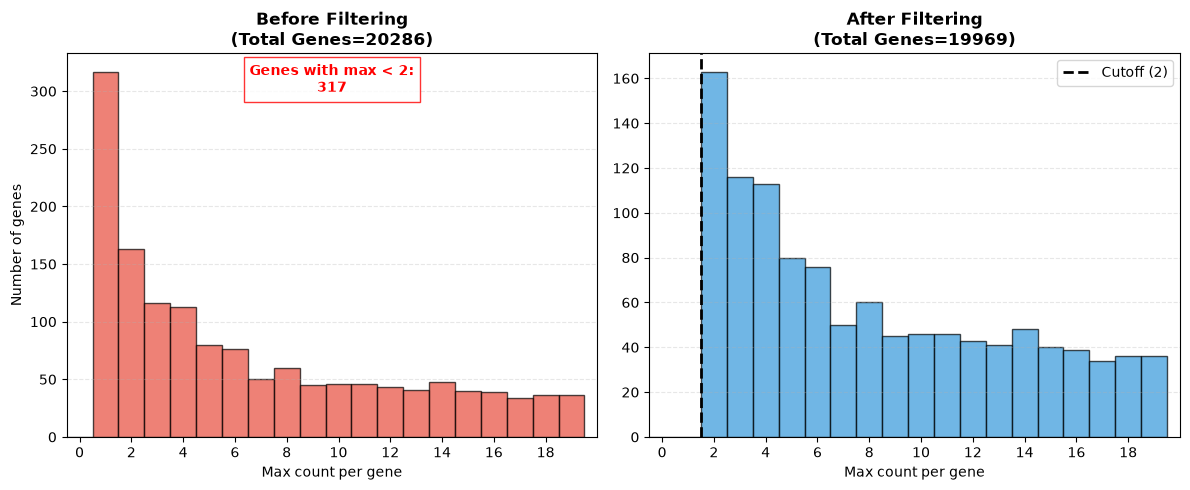

In [12]:
plot_gene_max_count_distribution(raw_data, clean_data, x_limit=20)

## Doublets (demonstration only)

We run the doublet filter to show how many cells it would remove, but the rest of the notebook continues from `clean_data`.

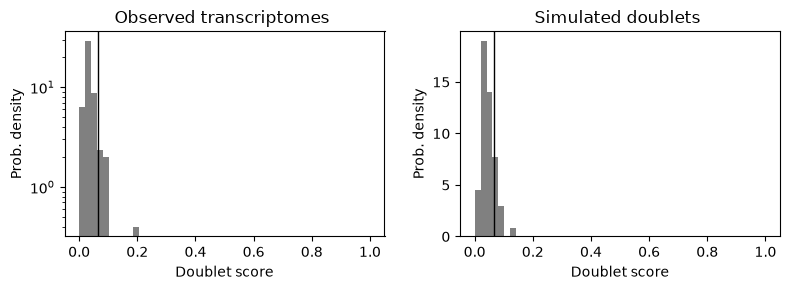

Cells removed as doublets: 12 / 124


In [13]:
# For demonstration only: the rest of the notebook continues from clean_data, not from no_doublets_data
no_doublets_data = filter_doublets(clean_data)

print(f"Cells removed as doublets: {clean_data.shape[0] - no_doublets_data.shape[0]} / {clean_data.shape[0]}")

# Normalization

## logCPM

### Normalize by library size

In [14]:
normalized_data = normalize_by_library_size(clean_data)

normalized_data.shape

(124, 19969)

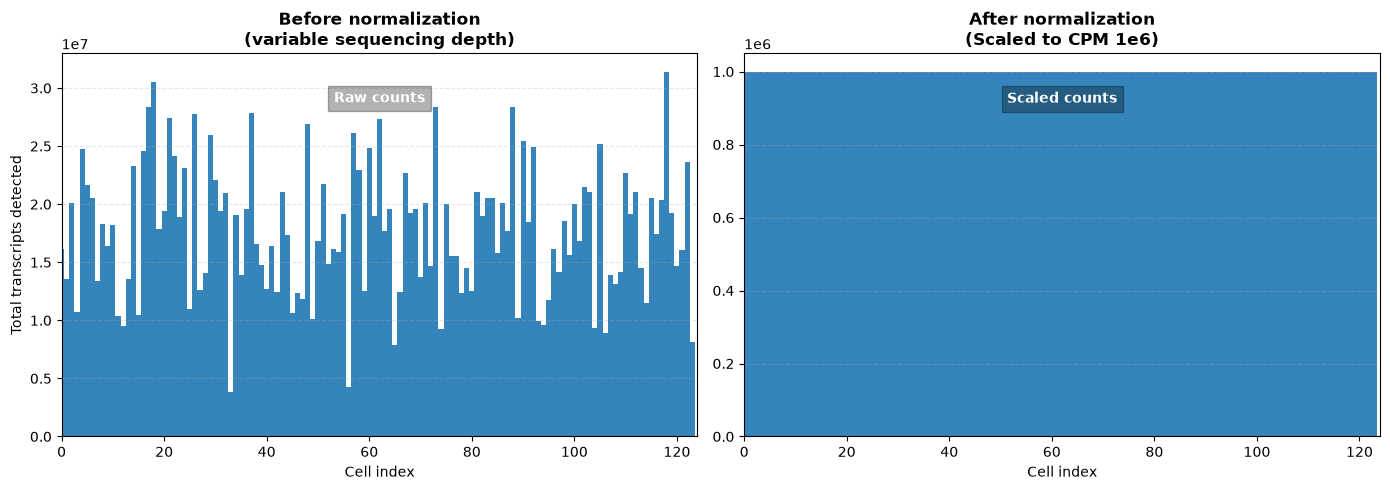

In [15]:
plot_normalization_comparison(clean_data, normalized_data, n_cells=normalized_data.shape[0])

### Log Transform

In [16]:
logged_data = log_transform(normalized_data)

logged_data.shape

(124, 19969)

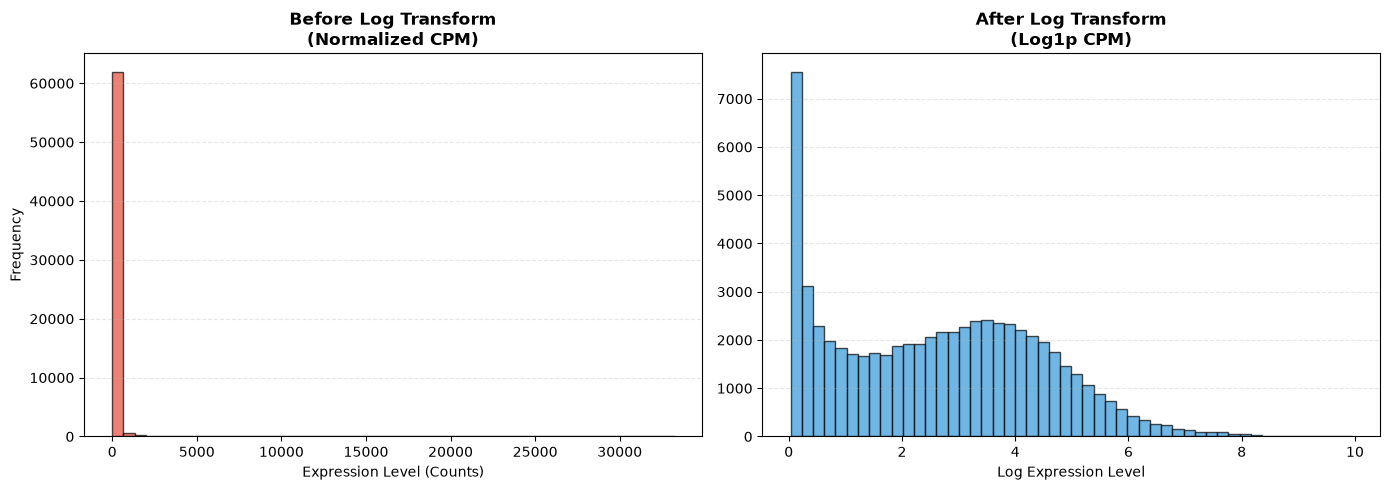

In [17]:
plot_log_transform_comparison(normalized_data, logged_data)

## Pearson residuals

In [18]:
pearsons_data = normalize_with_pearson(clean_data)

pearsons_data.shape

(124, 19969)

In [19]:
pearsons_data.head()

,FSTL1,AACS,RPS11,ELMO2,PNMA1,MMP2,SLMAP,TMEM216,SAMD4A,HAUS2,...,LCN1,IL17REL,GPX5,SPATA8,SNORA54,G6PC2,LOC440117,CCT8L2,CXorf66,SPRR3
cell_id,,,,,,,,,,,,,,,,,,,,,
GSM922271,-5.561452,3.358187,-1.842454,-9.539458,-6.033591,-7.219833,10.511294,11.135529,-8.928627,9.789517,...,-0.191689,-0.331892,-0.342764,-0.401838,-0.148492,-0.506602,-0.191689,-0.209977,-0.548188,-0.592989
GSM922256,11.135529,11.135529,-4.679018,-9.295936,-8.404540,-5.480073,11.135529,-3.711778,-6.804473,-3.379261,...,-0.175410,-0.303725,-0.313676,-0.367750,-0.135880,-0.463663,-0.175410,-0.192146,-0.501742,-0.542770
GSM922187,-9.401852,-8.398297,1.521474,-9.346130,11.135529,-7.121477,0.782223,-7.387591,-7.400335,11.135529,...,-0.213794,-0.370133,-0.382254,-0.448110,-0.165619,-0.564871,-0.213794,-0.234189,-0.611207,-0.661118
GSM922199,-8.652673,-8.165298,-5.738913,-9.356197,6.677128,-6.801504,7.360169,-6.509962,-8.534402,11.135529,...,-0.156376,-0.270785,-0.279659,-0.327881,-0.121134,-0.413429,-0.156376,-0.171297,-0.447399,-0.484005
GSM922150,-9.506937,1.620612,10.451324,11.135529,-7.612273,-8.155051,-8.394122,7.965196,11.135529,-6.674609,...,-0.237454,-0.411050,-0.424507,-0.497610,-0.183952,-0.627184,-0.237454,-0.260103,-0.678588,-0.733946
